In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import utils
import dynamics
import simulation

In [93]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [94]:
SEMI_MAJOR_AXIS = 6.778e6
GRAV = 3.986004418e14

In [95]:
initial_state = np.array([
    100.0,  # x, meters
    0.0,    # y
    0.0,    # z
    0.0,    # vx, m/s
    0.0,    # vy
    0.0,    # vz
]).reshape(6, 1)

n = dynamics.orbital_rate(SEMI_MAJOR_AXIS, GRAV)
dt = 0.01
T = 1000

t, X, U, X_est = simulation.simulate(n, initial_state, dt, T)

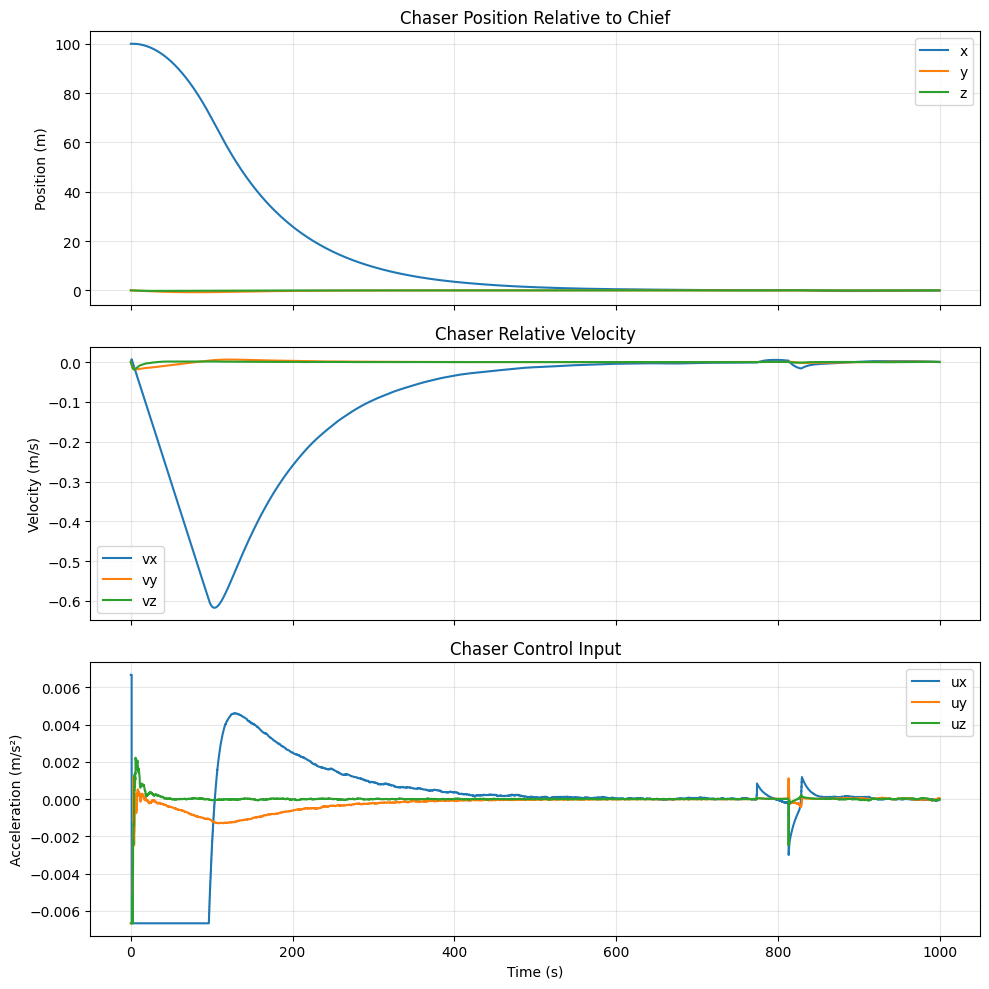

In [98]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

# Handles U with either len(t) or len(t)-1 samples.
t_control = t[:len(U)]

for i, axis in enumerate(("x", "y", "z")):
    axes[0].plot(t, X[:, i], label=axis)
    axes[1].plot(t, X[:, i + 3], label=f"v{axis}")
    axes[2].step(
        t_control, U[:, i],
        where="post", label=f"u{axis}"
    )

axes[0].set(
    title="Chaser Position Relative to Chief",
    ylabel="Position (m)",
)
axes[1].set(
    title="Chaser Relative Velocity",
    ylabel="Velocity (m/s)",
)
axes[2].set(
    title="Chaser Control Input",
    xlabel="Time (s)",
    ylabel="Acceleration (m/s²)",
)

for ax in axes:
    ax.legend()
    ax.grid(True, alpha=0.3)




fig.tight_layout()

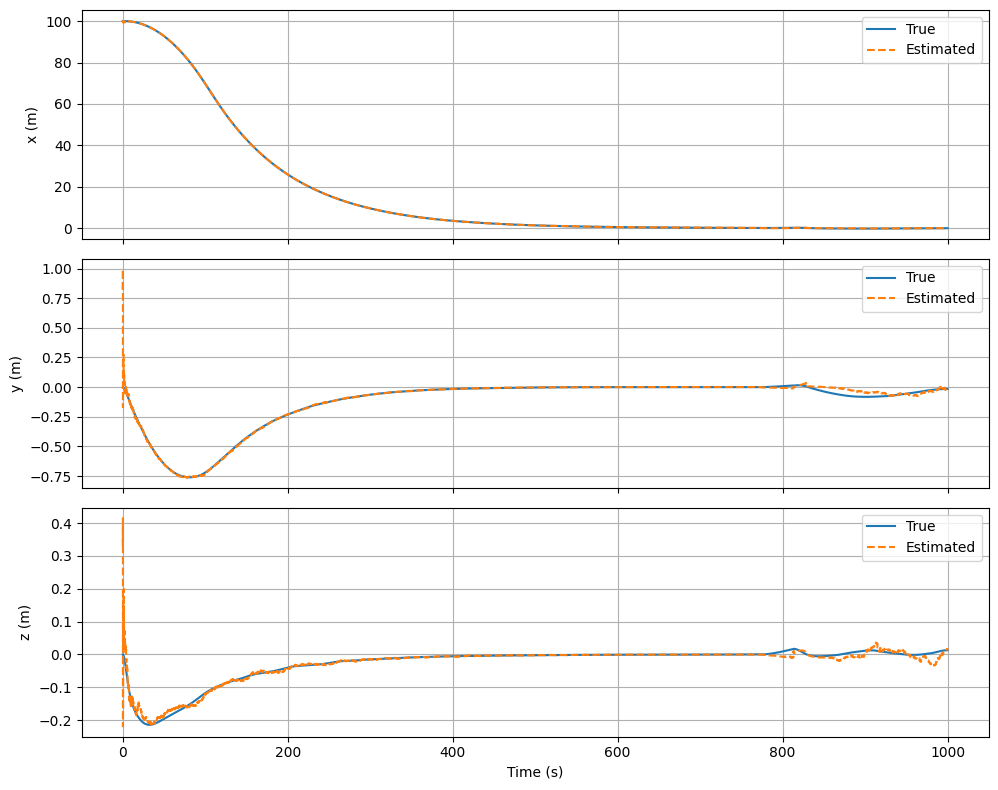

In [99]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

for i, axis in enumerate(("x", "y", "z")):
    axes[i].plot(t, X[:, i], label="True")
    axes[i].plot(t, X_est[:, i], "--", label="Estimated")
    axes[i].set_ylabel(f"{axis} (m)")
    axes[i].grid(True)
    axes[i].legend()

axes[-1].set_xlabel("Time (s)")
fig.tight_layout()
plt.show()